# The 1644 crisis of the Ming and cultural production
Did the fall of the Ming (rebellions from 1628, Beijing taken in 1644, Qing conquest of the south until 1662) change how many people were born, trained and active in arts and science on the territory? Did the decline start before 1644?

Visual only, no statistics. **Territory**: individuals matched to the Ming, Later Jin, Li Zicheng (Shun), Southern Ming or Qing polity (`humans_clean_enriched_v3`), taken together so that a change of dynasty is not mistaken for a change of population. **Dates and occupations**: `cultura_enriched_v3.2` (copy taken before the polity ingestion, because the live file is being written). **Domains**: an individual is a *cultural producer* when one Wikidata occupation is classified "Culture", *science* when one is "Discovery/Science", *official* when one is "Leadership".

In [1]:
import json
import tempfile

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.ticker import MaxNLocator
from shapely.geometry import shape
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2_before_polities.duckdb'
POLITY_DB_PATH = '../../data/cultura/humans_clean_enriched_v3.duckdb'
COUNTRIES_PATH = '../../data/ne_110m_admin_0_countries.geojson'

MING = 'Ming Dynasty'
TERRITORY_POLITIES = [MING, 'Later Jin Dynasty', 'Li Zicheng', 'Southern Ming', 'Qing Dynasty']
BIRTH_START, BIRTH_END = 1500, 1750
ACTIVE_START, ACTIVE_END = 1550, 1720
TIMELINE_BIRTHS = (1580, 1700)
REFERENCE_YEAR = 1600
MAP_EXTENT = (97, 125, 18, 43)
NORTH_LATITUDE = 34
GENERATIONS = {'born 1580-1619': (1580, 1620), 'born 1620-1659': (1620, 1660), 'born 1660-1699': (1660, 1700)}
TOP_NAMES = 25

CRISIS_START, FALL_OF_BEIJING, CRISIS_END = 1628, 1644, 1662
EVENTS = {1618: 'Later Jin war', 1628: 'Shaanxi rebellions', 1644: 'fall of Beijing', 1662: 'end of Southern Ming'}

DOMAINS = {'Culture': 'cultural producers', 'Discovery/Science': 'science', 'Leadership': 'officials'}
DOMAIN_COLORS = {'cultural producers': BLUE, 'science': GREEN, 'officials': ORANGE, 'all individuals': SLATE}
SOURCE_COLORS = {'CBDB': LIGHT_BLUE, 'other sources': ORANGE}
REGION_COLORS = {'North China': RED, 'Centre and South': BLUE}
CRISIS_SHADE = {'color': PALE_GREY, 'lw': 0, 'zorder': 0}

apply_style()

## External data
Country outlines (Natural Earth 1:110m) for the maps. The event years (1618, 1628, 1644, 1662) are the only constants not read from the database; the end of the Ming is read from its Cliopatria territories as a check.

## Load data
### Individuals of the territory

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"ATTACH '{POLITY_DB_PATH}' AS polity_db (READ_ONLY)")
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")

con.sql('''
    CREATE TEMP TABLE territory_individuals AS
    SELECT DISTINCT entity.qid AS qid
    FROM   (SELECT entity, unnest(polity) AS polity_match FROM polity_db.individual_enriched)
    WHERE  list_contains($names, polity_match.polity.name)
''', params={'names': TERRITORY_POLITIES})

people = con.sql('''
    SELECT territory_individuals.qid,
           individual_enriched.entity.label_en                   AS name,
           individual_enriched.entity.description                AS description,
           individual_enriched.birth_date.year                   AS birth_year,
           individual_enriched.birth_date.source                 AS birth_source,
           individual_enriched.death_date.year                   AS death_year,
           individual_enriched.start_of_active_life.year         AS active_start,
           individual_enriched.end_of_active_life.year           AS active_end,
           individual_enriched.entity.description ILIKE '%CBDB%' AS is_cbdb,
           len(individual.sitelink)                              AS sitelinks,
           coalesce(birth_place.coordinates.latitude, death_place.coordinates.latitude)   AS latitude,
           coalesce(birth_place.coordinates.longitude, death_place.coordinates.longitude) AS longitude
    FROM   territory_individuals
    JOIN   individual_enriched ON individual_enriched.entity.qid = territory_individuals.qid
    JOIN   individual          ON individual.entity.qid = territory_individuals.qid
    LEFT JOIN place AS birth_place ON birth_place.entity.qid = individual.place_of_birth.entity.qid
    LEFT JOIN place AS death_place ON death_place.entity.qid = individual.place_of_death.entity.qid
''').pl()

assert people['qid'].is_unique
print(f"territory individuals: {people.height:,}")
print(f"  born {BIRTH_START}-{BIRTH_END - 1}: {people['birth_year'].is_between(BIRTH_START, BIRTH_END - 1).sum():,}")
people.sample(5, seed=42)

territory individuals: 49,555
  born 1500-1749: 21,077


qid,name,description,birth_year,birth_source,death_year,active_start,active_end,is_cbdb,sitelinks,latitude,longitude
str,str,str,i64,str,i64,i64,i64,bool,i64,f64,f64
"""Q45534415""","""Zhang Mengli""","""Ming dynasty person CBDB = 130…",1533,"""wikidata""",1597,1574,1591,true,1,null,null
"""Q45672789""","""Xie Xian""","""Ming dynasty person CBDB = 201…",1474,"""wikidata""",1534,1513,1532,true,1,null,null
"""Q45479330""","""Yang Zhaolu""","""Qing dynasty person CBDB = 767…",1623,"""wikidata""",1683,1659,1680,true,0,null,null
"""Q45583596""","""Zheng Luan""","""Qing dynasty person CBDB = 837…",1782,"""wikidata""",1853,1823,1839,true,0,null,null
"""Q11085039""","""Fang Bangji""","""Qing dynasty politician""",1701,"""wikidata""",1750,1745,1750,false,1,null,null


### Domains (meta occupation of the Wikidata occupations)

In [3]:
person_domains = con.sql('''
    WITH person_occupation AS (
        SELECT territory_individuals.qid, unnest(individual.occupation).entity.qid AS occupation_qid
        FROM   territory_individuals
        JOIN   individual ON individual.entity.qid = territory_individuals.qid
    )
    SELECT DISTINCT person_occupation.qid, occupation.meta_occupation
    FROM   person_occupation
    JOIN   occupation ON occupation.entity.qid = person_occupation.occupation_qid
    WHERE  list_contains($domains, occupation.meta_occupation)
''', params={'domains': list(DOMAINS)}).pl().with_columns(pl.col('meta_occupation').replace(DOMAINS).alias('domain'))

top_occupations = con.sql('''
    WITH person_occupation AS (
        SELECT territory_individuals.qid, unnest(individual.occupation).entity.qid AS occupation_qid
        FROM   territory_individuals
        JOIN   individual ON individual.entity.qid = territory_individuals.qid
    )
    SELECT occupation.meta_occupation, occupation.entity.label_en AS occupation, COUNT(DISTINCT person_occupation.qid) AS individuals
    FROM   person_occupation
    JOIN   occupation ON occupation.entity.qid = person_occupation.occupation_qid
    WHERE  list_contains($domains, occupation.meta_occupation)
    GROUP BY occupation.meta_occupation, occupation.entity.label_en
    QUALIFY row_number() OVER (PARTITION BY occupation.meta_occupation ORDER BY individuals DESC) <= 6
    ORDER BY occupation.meta_occupation, individuals DESC
''', params={'domains': list(DOMAINS)}).pl()
print(person_domains.group_by('domain').len())
top_occupations

shape: (3, 2)
┌────────────────────┬───────┐
│ domain             ┆ len   │
│ ---                ┆ ---   │
│ str                ┆ u32   │
╞════════════════════╪═══════╡
│ cultural producers ┆ 2933  │
│ officials          ┆ 15231 │
│ science            ┆ 926   │
└────────────────────┴───────┘


meta_occupation,occupation,individuals
str,str,i64
"""Culture""","""poet""",1513
"""Culture""","""painter""",742
"""Culture""","""calligrapher""",514
"""Culture""","""writer""",445
"""Culture""","""artist""",79
…,…,…
"""Leadership""","""military personnel""",519
"""Leadership""","""missionary""",283
"""Leadership""","""Catholic priest""",123


### Ming territory of 1600 and end of the Ming

In [4]:
ming = con.sql('''
    SELECT territory.start_year, territory.end_year, territory.geometry
    FROM   polity, unnest(polity.territories) AS unnested(territory)
    WHERE  polity.name = $name AND territory.geometry IS NOT NULL
''', params={'name': MING}).pl()
con.close()

ming_1600 = shape(json.loads(ming.filter(pl.col('start_year') <= REFERENCE_YEAR, pl.col('end_year') >= REFERENCE_YEAR)['geometry'][0])).buffer(0)
countries = gpd.read_file(COUNTRIES_PATH)
print('last year of the Ming territory in Cliopatria:', ming['end_year'].max())

last year of the Ming territory in Cliopatria: 1644


## Preprocessing
### Births per decade, by source and by domain

In [5]:
born = people.filter(pl.col('birth_year').is_between(BIRTH_START, BIRTH_END - 1)).with_columns(
    (pl.col('birth_year') // 10 * 10).alias('decade'),
    pl.when(pl.col('is_cbdb')).then(pl.lit('CBDB')).otherwise(pl.lit('other sources')).alias('source'),
)
print(f"born {BIRTH_START}-{BIRTH_END - 1}: {born.height:,}, birth year estimated: {(born['birth_source'] == 'estimated').sum():,}")

births_by_source = born.group_by('decade', 'source').len().pivot(on='source', index='decade', values='len').fill_null(0).sort('decade')

born_domains = born.join(person_domains, on='qid', how='inner')
births_by_domain = (
    pl.concat([born.select('decade', pl.lit('all individuals').alias('domain')), born_domains.select('decade', 'domain')])
    .group_by('decade', 'domain').len()
    .pivot(on='domain', index='decade', values='len').fill_null(0).sort('decade')
)
assert births_by_domain['all individuals'].sum() == born.height
births_by_domain

born 1500-1749: 21,077, birth year estimated: 3,020


decade,all individuals,officials,cultural producers,science
i64,u32,u32,u32,u32
1500,920,664,32,16
1510,1063,758,23,17
1520,943,614,27,18
1530,1088,610,13,16
1540,863,631,22,14
…,…,…,…,…
1700,846,113,42,11
1710,762,121,39,6
1720,793,90,50,11


### Individuals active each year, by domain
Active life from `start_of_active_life` to `end_of_active_life`.

In [6]:
def active_per_year(frame):
    return (
        frame.filter(pl.col('active_start').is_not_null())
        .select(pl.int_ranges('active_start', pl.col('active_end') + 1).alias('year'))
        .explode('year')
        .filter(pl.col('year').is_between(ACTIVE_START, ACTIVE_END))
        .group_by('year').len().sort('year')
    )


active = {'all individuals': active_per_year(people)}
for domain in DOMAINS.values():
    active[domain] = active_per_year(people.join(person_domains.filter(pl.col('domain') == domain), on='qid'))
pl.DataFrame({'year': [1600, 1620, 1630, 1644, 1660, 1680, 1700]}).join(
    pl.concat([frame.with_columns(pl.lit(name).alias('domain')) for name, frame in active.items()])
    .pivot(on='domain', index='year', values='len'), on='year', how='left')

year,all individuals,cultural producers,science,officials
i64,u32,u32,u32,u32
1600,1622,59,27,1003
1620,863,95,24,384
1630,1164,122,21,481
1644,1372,152,25,308
1660,2208,249,36,280
1680,2036,166,30,215
1700,1391,140,18,132


### Cultural producers' lives, birth to death
One line per cultural producer born 1580-1699, sorted by birth: childhood and training (birth → start of active life) and active life (start → end).

In [7]:
culture_lives = (
    born.join(person_domains.filter(pl.col('domain') == 'cultural producers'), on='qid')
    .filter(pl.col('birth_year').is_between(*TIMELINE_BIRTHS, closed='left'), pl.col('active_start').is_not_null())
    .sort('birth_year', 'active_start')
    .with_row_index('rank')
)
culture_lives = culture_lives.with_columns(
    pl.when(pl.col('active_start') > CRISIS_END).then(pl.lit(f'active life starts after {CRISIS_END}'))
    .when(pl.col('active_start') >= CRISIS_START).then(pl.lit(f'active life starts {CRISIS_START}-{CRISIS_END}'))
    .otherwise(pl.lit(f'active life starts before {CRISIS_START}')).alias('crisis_stage')
)
print(f'cultural producers on the timeline: {culture_lives.height:,}')
culture_lives.group_by('crisis_stage').len()

cultural producers on the timeline: 772


crisis_stage,len
str,u32
"""active life starts 1628-1662""",331
"""active life starts before 1628""",89
"""active life starts after 1662""",352


### Region of the individuals with a located birth or death place
Only individuals with coordinates (birthplace, else deathplace). Most are matched to the Ming or Qing through their country of citizenship alone, so they have no place below the empire. North China = latitude ≥ 34° (Shaanxi, Shanxi, Henan north, Hebei and Beijing, Shandong), where the rebellions and the 1644 conquest took place.

In [8]:
located = born.filter(pl.col('latitude').is_not_null()).with_columns(
    pl.when(pl.col('latitude') >= NORTH_LATITUDE).then(pl.lit('North China')).otherwise(pl.lit('Centre and South')).alias('region')
)
located_culture = located.join(person_domains.filter(pl.col('domain') == 'cultural producers'), on='qid', how='semi')
births_by_region = located.group_by('decade', 'region').len().pivot(on='region', index='decade', values='len').fill_null(0).sort('decade')
print(f'located individuals: {located.height:,} of {born.height:,} ({located.height / born.height:.1%}), cultural producers: {located_culture.height:,}')
births_by_region

located individuals: 830 of 21,077 (3.9%), cultural producers: 302


decade,North China,Centre and South
i64,u32,u32
1500,4,34
1510,6,22
1520,5,27
1530,3,28
1540,3,29
…,…,…
1700,15,14
1710,14,17
1720,13,16


## Figures
### Figure 1: Individuals born per decade on the Ming / Qing territory

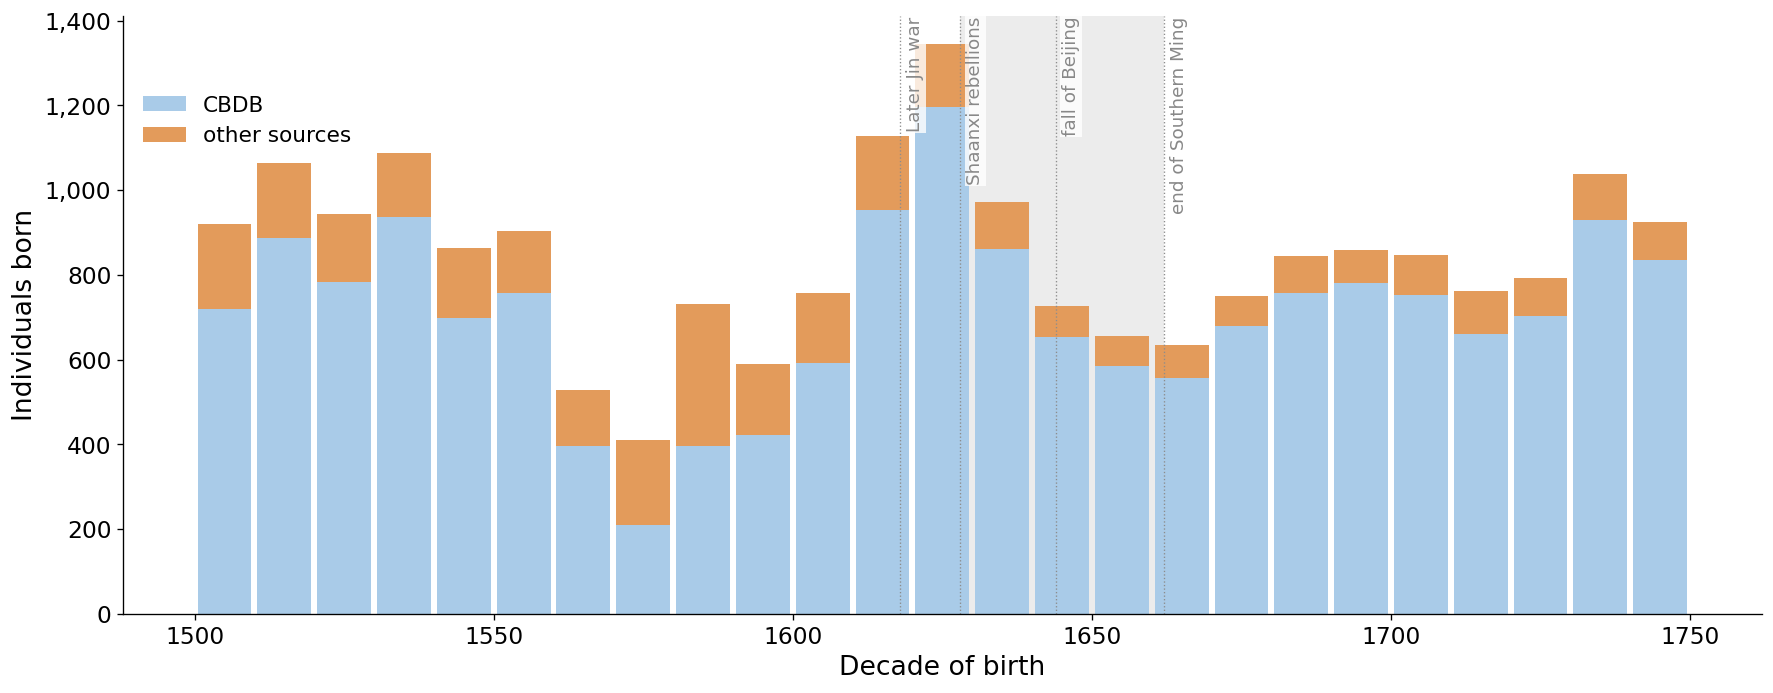

In [9]:
def mark_crisis(ax, labels=True):
    ax.axvspan(CRISIS_START, CRISIS_END, **CRISIS_SHADE)
    for year, label in EVENTS.items():
        ax.axvline(year, **REFERENCE_LINE)
        if labels:
            ax.text(year + 1, 1.0, label, transform=ax.get_xaxis_transform(), rotation=90, va='top', fontsize=SMALL_LEGEND_FONTSIZE, color=MUTED_TEXT,
                    bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.8, 'pad': 1})


fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
bottom = np.zeros(births_by_source.height)
for source in SOURCE_COLORS:
    ax.bar(births_by_source['decade'] + 5, births_by_source[source], width=9, bottom=bottom, color=SOURCE_COLORS[source], label=source)
    bottom += births_by_source[source].to_numpy()
mark_crisis(ax)
ax.set_xlabel('Decade of birth')
ax.set_ylabel('Individuals born')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(loc='upper left', bbox_to_anchor=(0, 0.9))
plt.tight_layout()
plt.show()

### Figure 2: Births per decade by domain (cultural producers, science, officials)
Each panel has its own scale; the shape matters, not the level.

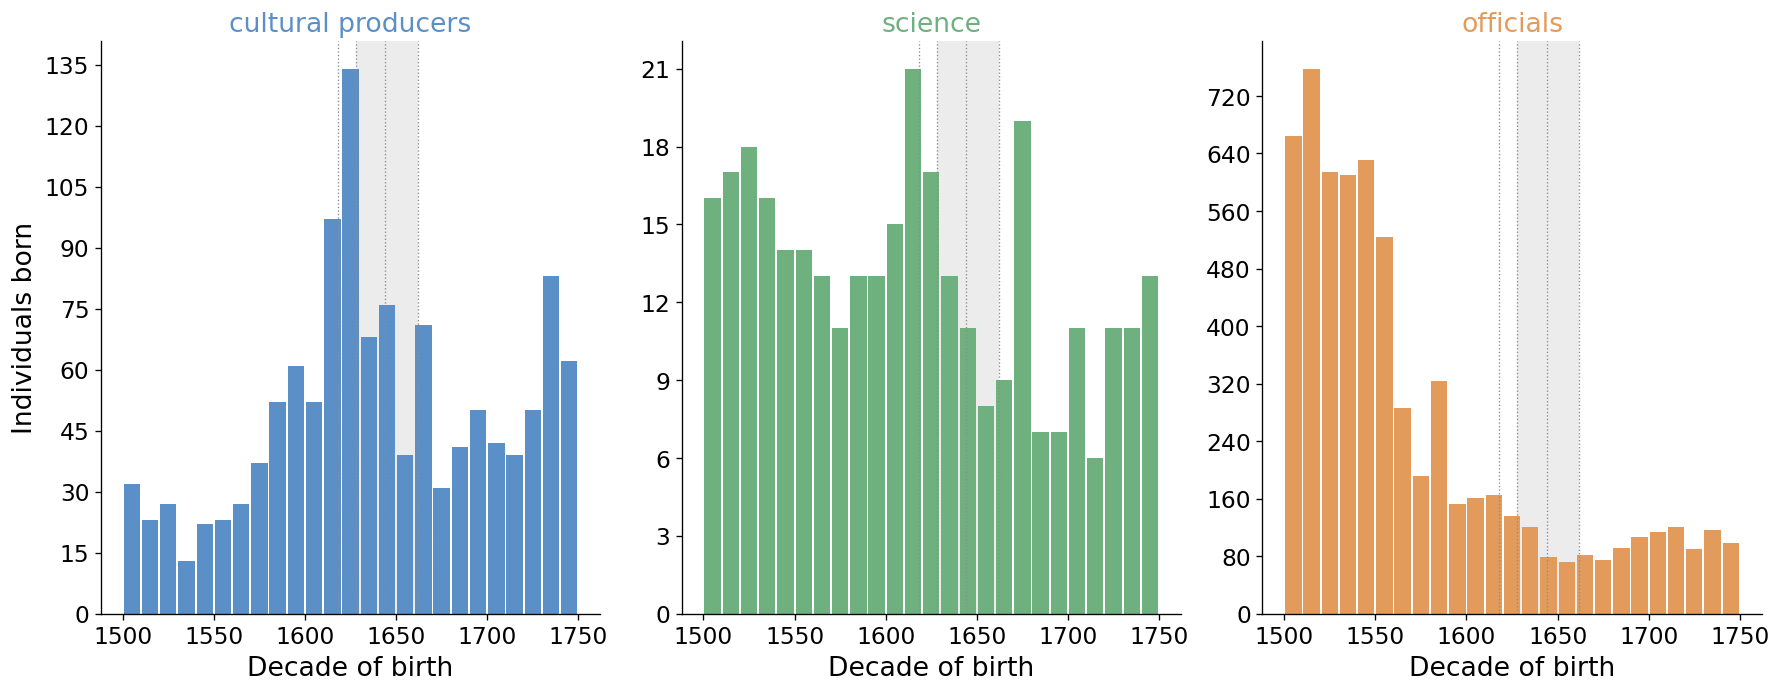

In [10]:
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE_WIDE, sharex=True)
for ax, domain in zip(axes, DOMAINS.values()):
    ax.bar(births_by_domain['decade'] + 5, births_by_domain[domain], width=9, color=DOMAIN_COLORS[domain])
    mark_crisis(ax, labels=False)
    ax.set_title(domain, color=DOMAIN_COLORS[domain])
    ax.set_xlabel('Decade of birth')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel('Individuals born')
plt.tight_layout()
plt.show()

### Figure 3: Individuals active each year, by domain

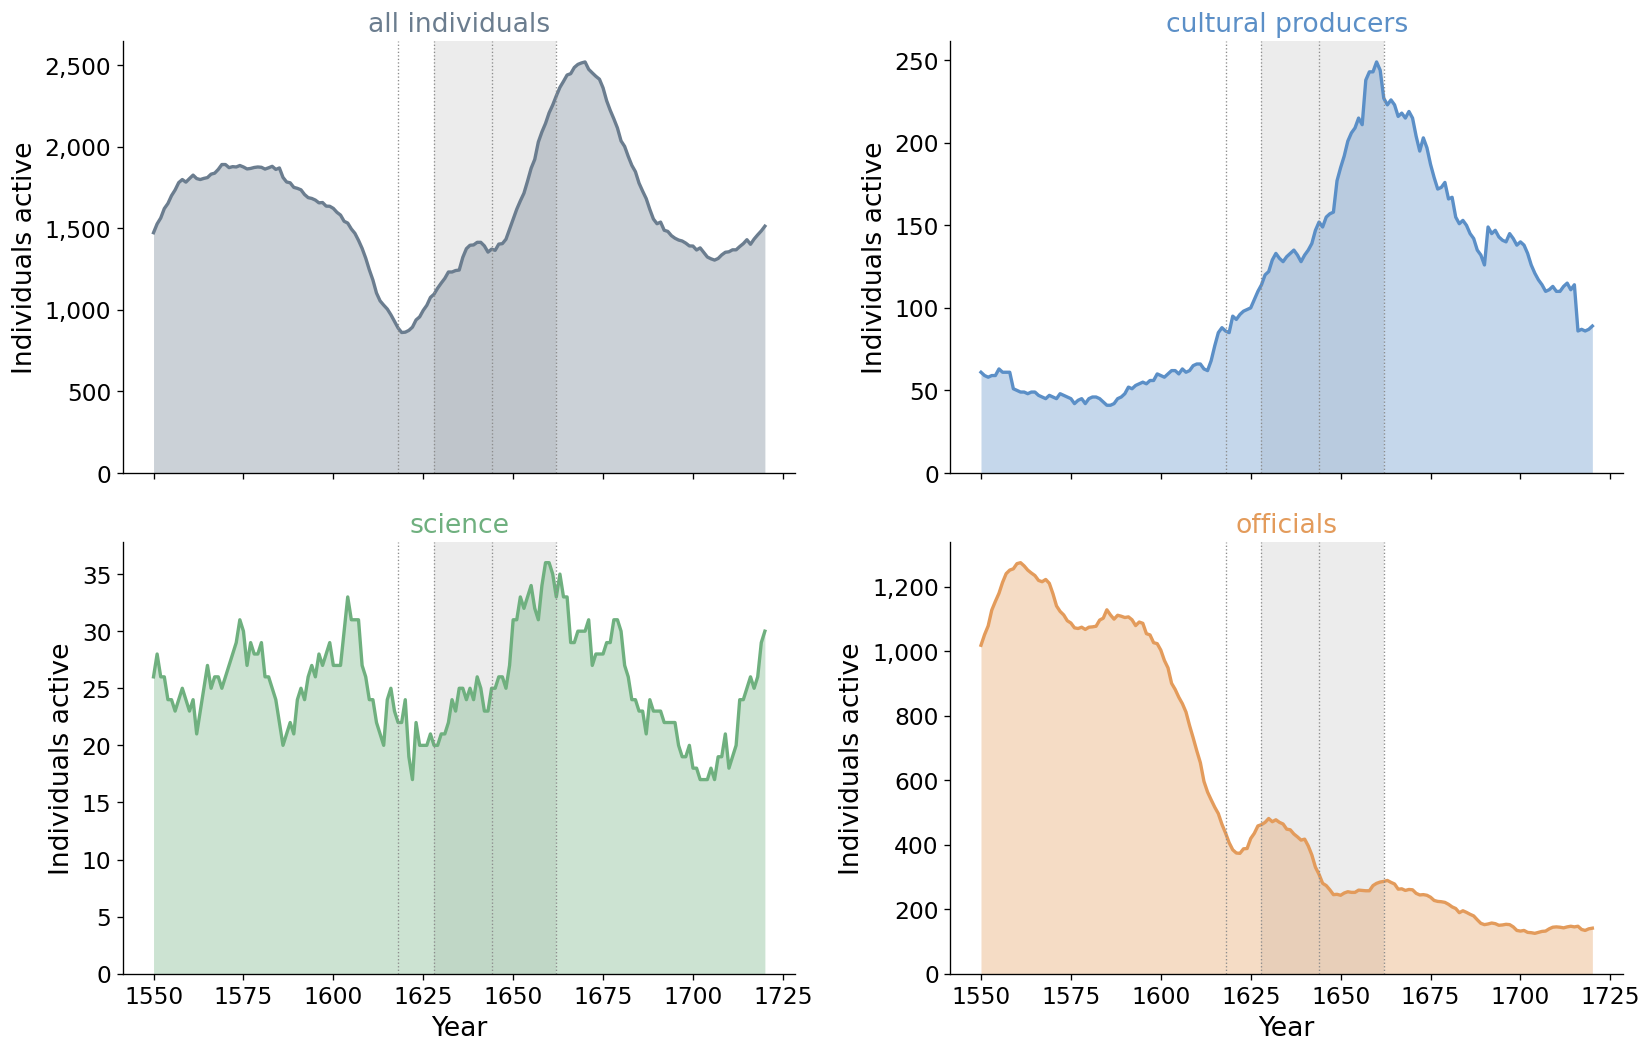

In [11]:
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_GRID, sharex=True)
for ax, (name, frame) in zip(axes.flat, active.items()):
    ax.fill_between(frame['year'], frame['len'], color=DOMAIN_COLORS[name], alpha=0.35, lw=0)
    ax.plot(frame['year'], frame['len'], color=DOMAIN_COLORS[name])
    mark_crisis(ax, labels=False)
    ax.set_title(name, color=DOMAIN_COLORS[name])
    ax.set_ylabel('Individuals active')
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(THOUSANDS)
for ax in axes[1]:
    ax.set_xlabel('Year')
plt.tight_layout()
plt.show()

### Figure 4: Lives of the cultural producers born 1580-1699
Light: birth to start of active life (childhood and training). Dark: active life. Grey band: 1628-1662.

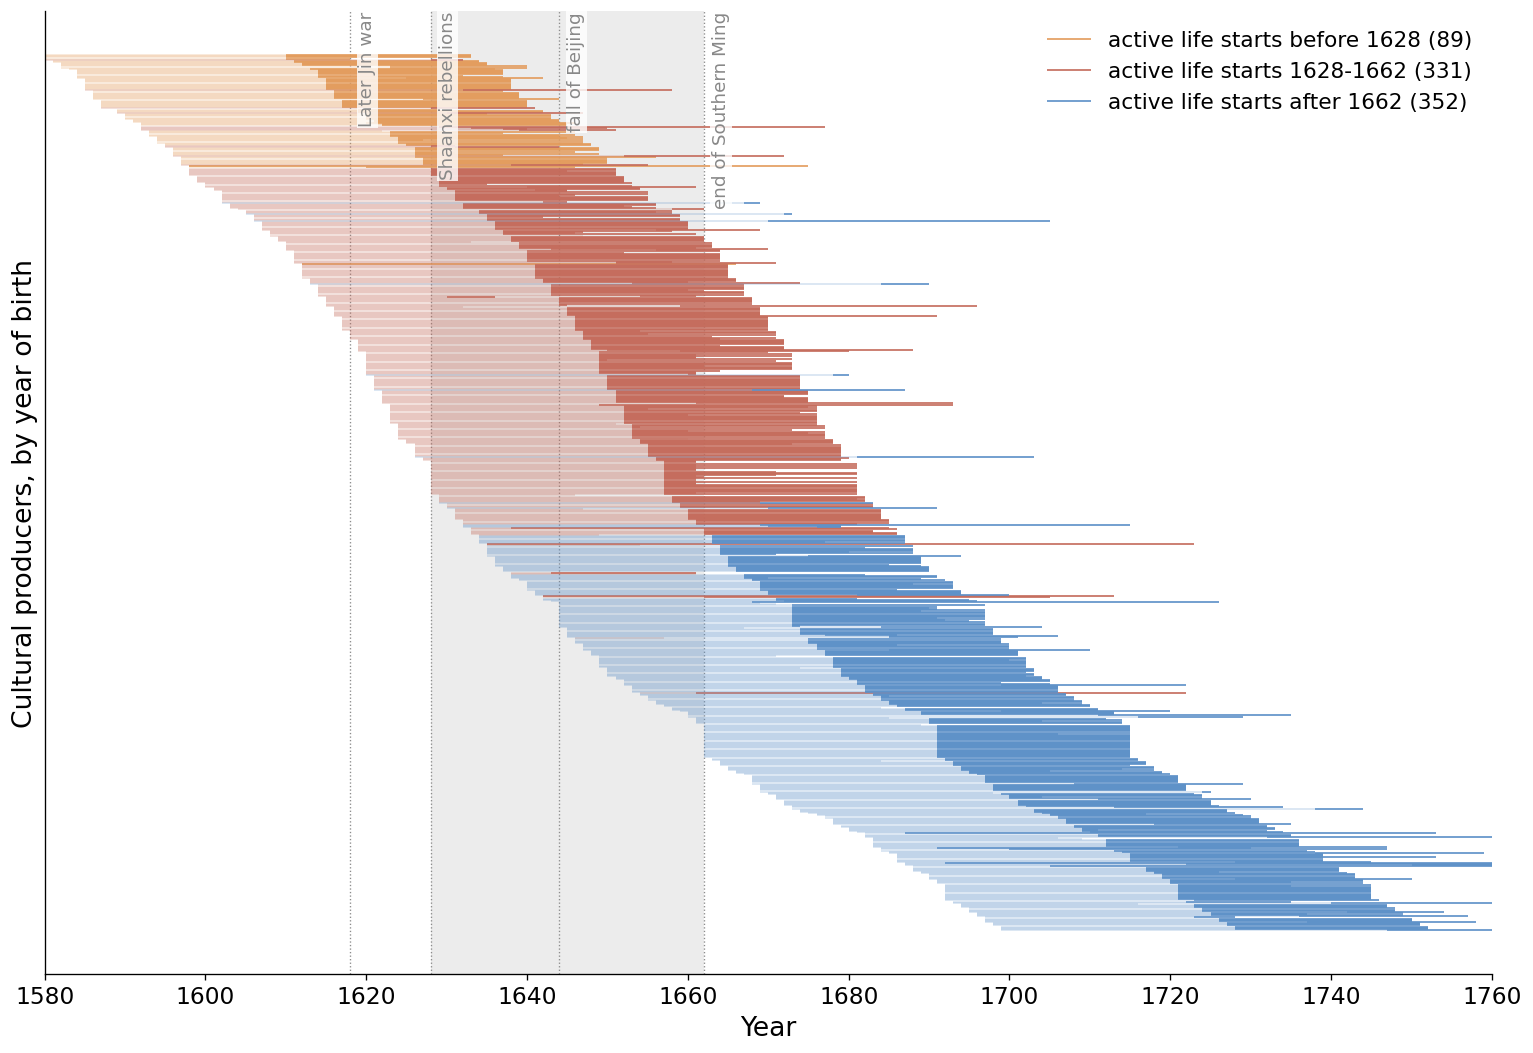

In [12]:
STAGE_COLORS = {f'active life starts before {CRISIS_START}': ORANGE,
                f'active life starts {CRISIS_START}-{CRISIS_END}': RED,
                f'active life starts after {CRISIS_END}': BLUE}

fig, ax = plt.subplots(figsize=(13, 9))
mark_crisis(ax)
for stage, color in STAGE_COLORS.items():
    rows = culture_lives.filter(pl.col('crisis_stage') == stage)
    ax.hlines(rows['rank'], rows['birth_year'], rows['active_start'], color=color, alpha=0.25, lw=1)
    ax.hlines(rows['rank'], rows['active_start'], rows['active_end'], color=color, lw=1, label=f'{stage} ({rows.height:,})')
ax.set_xlim(TIMELINE_BIRTHS[0], ACTIVE_END + 40)
ax.set_xlabel('Year')
ax.set_ylabel('Cultural producers, by year of birth')
ax.set_yticks([])
ax.invert_yaxis()
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Figure 5: Births per decade by region (located individuals only)

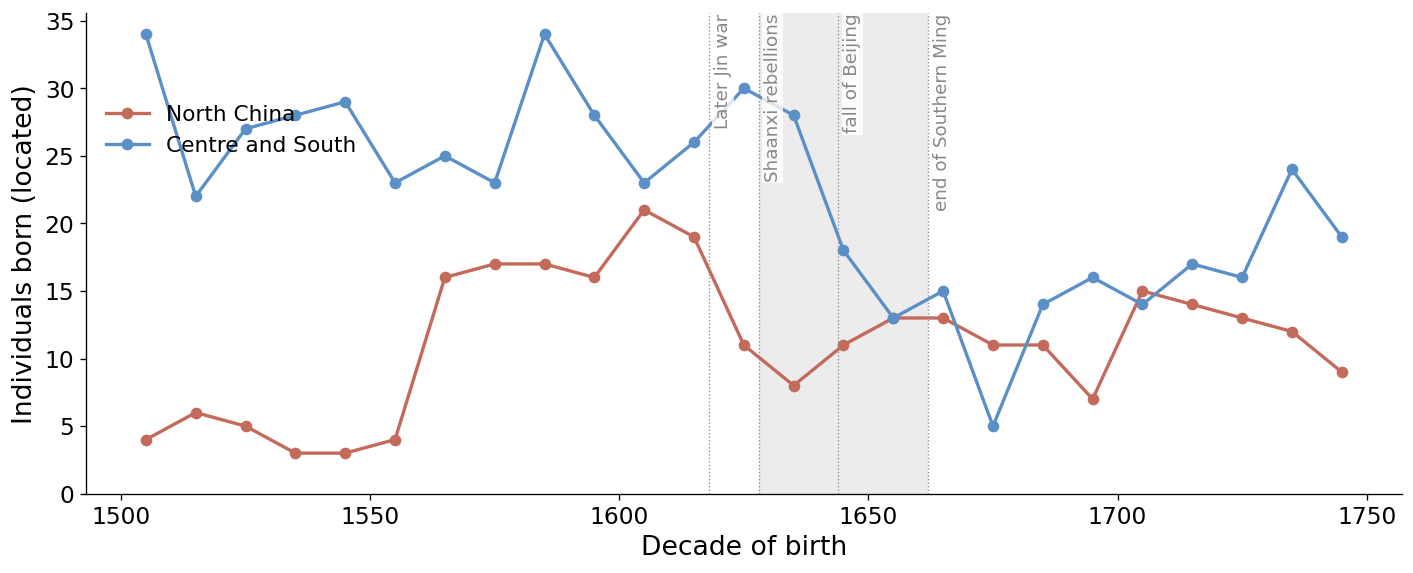

In [13]:
fig, ax = plt.subplots(figsize=FIGSIZE)
for region, color in REGION_COLORS.items():
    ax.plot(births_by_region['decade'] + 5, births_by_region[region], color=color, marker='o', label=region)
mark_crisis(ax)
ax.set_xlabel('Decade of birth')
ax.set_ylabel('Individuals born (located)')
ax.set_ylim(bottom=0)
ax.legend(loc='upper left', bbox_to_anchor=(0, 0.85))
plt.tight_layout()
plt.show()

### Figure 6: Where the located individuals were born, three generations
Outline: Ming territory in 1600. Blue: cultural producers; grey: others. Dashed line: 34° N.

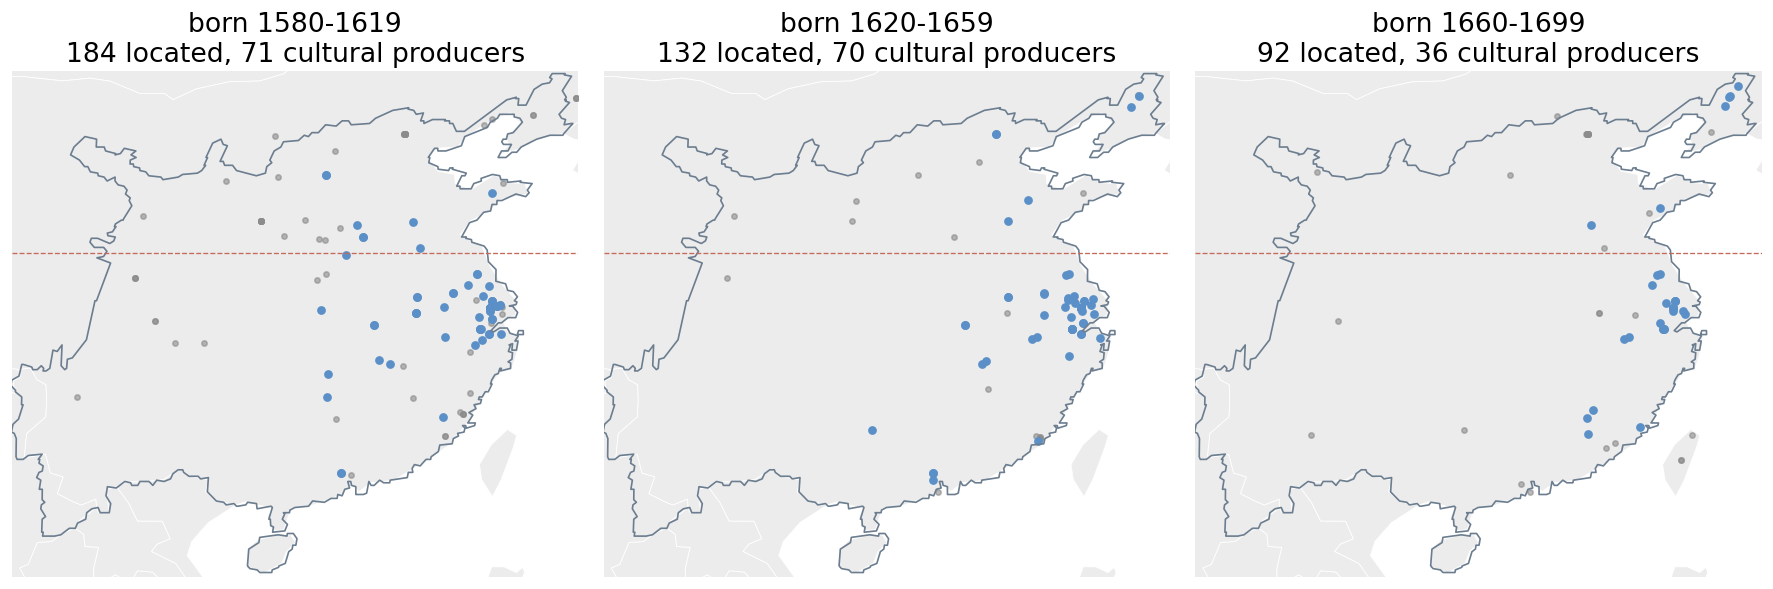

In [14]:
culture_qids = set(located_culture['qid'])
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE_WIDE)
for ax, (label, (start, end)) in zip(axes, GENERATIONS.items()):
    countries.plot(ax=ax, color=PALE_GREY, edgecolor='white', lw=0.5)
    gpd.GeoSeries([ming_1600]).boundary.plot(ax=ax, color=MAP_BORDER_COLOR, lw=1)
    generation = located.filter(pl.col('birth_year').is_between(start, end, closed='left'))
    is_culture = generation['qid'].is_in(culture_qids)
    others, culture = generation.filter(~is_culture), generation.filter(is_culture)
    ax.scatter(others['longitude'], others['latitude'], s=10, color=GREY, alpha=0.6)
    ax.scatter(culture['longitude'], culture['latitude'], s=18, color=BLUE)
    ax.axhline(NORTH_LATITUDE, color=RED, ls='--', lw=0.8)
    ax.set_xlim(*MAP_EXTENT[:2])
    ax.set_ylim(*MAP_EXTENT[2:])
    ax.set_title(f'{label}\n{generation.height} located, {culture.height} cultural producers')
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## Who they are
### Cultural producers whose active life starts during the crisis (1628-1662), most linked first

In [15]:
(
    culture_lives.filter(pl.col('crisis_stage') == f'active life starts {CRISIS_START}-{CRISIS_END}')
    .sort('sitelinks', descending=True)
    .select('name', 'description', 'birth_year', 'death_year', 'active_start', 'active_end', 'sitelinks')
    .head(TOP_NAMES)
)

name,description,birth_year,death_year,active_start,active_end,sitelinks
str,str,i64,i64,i64,i64,i64
"""Kangxi Emperor""","""3rd Emperor of the Qing dynast…",1654,1722,1661,1722,64
"""Shunzhi Emperor""","""Qing Dynasty emperor of China …",1638,1661,1643,1661,52
"""Shitao""","""Chinese painter and poet (1642…",1642,1707,1662,1705,43
"""Li Yu""","""Chinese writer（1611—1680）""",1611,1680,1651,1658,41
"""Johann Adam Schall von Bell""","""German astronomer and Jesuit m…",1592,1666,1633,1650,30
…,…,…,…,…,…,…
"""Chen Yuanyuan""","""poet, Chinese concubine (1624–…",1624,1681,1653,1677,12
"""Xiao Yuncong""","""Chinese painter (1596-1673)""",1596,1673,1652,1672,11
"""Shi Kefa""","""Ming Dynasty general""",1601,1645,1641,1645,11


## What the data shows
**1. The training of the next generation is hit (Figure 2, left).** The number of cultural producers born per decade rises steadily from the 1570s to a peak in the 1620s (134), then halves for the cohorts born 1630-1659 (68, 76, 39). Those are the children whose youth and training fell in the rebellions and the conquest. They recover only partly from the 1660s, and reach the level of the 1620s again only with the cohorts born in the 1730s. The 1620s peak holds without the birth years rounded to 1620 (21 individuals).

**2. Production itself does not collapse during the crisis; it peaks just after it (Figures 3 and 4).** The number of active cultural producers rises through 1628-1662 and reaches its maximum around 1660-1665. These are the cohorts born 1600-1630, trained under the late Ming and active during and after the fall (the generation of Wu Weiye, Huang Zongxi, Li Yu, Gu Yanwu and Wang Fuzhi, born 1609-1619). The decline of active producers comes later, from the 1670s, when the smaller cohorts born during the crisis should have taken over. In this data the crisis shows up in production with a delay of about one generation.

**3. Cause or consequence?** Two signals come *before* 1644. (a) Officials (Figure 2, right; Figure 3, bottom right) fall sharply from about 1595, and the number of all active individuals reaches its low point around 1620. (b) In the North (Figure 5), located births drop with the 1620s cohort, in the rebellion zone, while the Centre and South keep their level until the 1640s cohort, when the Qing conquest reached Jiangnan. The timing follows the geography of the crisis: North first, South about twenty years later. Cultural production keeps growing while the state weakens, so in this data the decline of culture looks like a **consequence** of the crisis, through the training of the next generation, not a cause of it.

**4. Science is too thin to read.** 6-21 science births per decade; no clear signal.

**Caveats.** Figures 1, 2 and 3 mostly reflect CBDB (85-90% of individuals). The fall of officials from about 1595 and the low of 1560-1590 births are partly coverage effects of CBDB's Ming lists, not necessarily fewer people. 92% of the individuals are placed on the territory only by their country of citizenship (Ming / Qing), so Figures 5 and 6 rest on only 830 people with a birth or death place (8-30 per decade and region). Active lives are mostly estimated from birth dates (birth + cohort median age), so Figure 3 is a smoothed, shifted version of the births.